## 1. Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error


Importing plotly failed. Interactive plots will not work.


### 2. LOAD DATASET & PREPROCESSING
Membersihkan data dari nilai 0 (hari libur toko) agar tidak merusak perhitungan error (MAPE) pada model Prophet.

In [2]:
sheet_name = "surya_kaleng" 
df = pd.read_excel("dataset/data_clean_ok.xlsx", sheet_name=sheet_name)

df['ds'] = pd.to_datetime(df['ds'])
df = df.sort_values('ds').dropna()

# Mengubah penjualan 0 menjadi NaN
df.loc[df['y'] == 0, 'y'] = np.nan

df.tail() 

,ds,y
1087,2025-12-27,92.0
1088,2025-12-28,97.0
1089,2025-12-29,127.0
1090,2025-12-30,105.0
1091,2025-12-31,103.0


### 3. SPLIT DATA (TRAIN & TEST)
Membagi data uji (Test) secara dinamis tepat 14 hari terakhir sesuai dengan Lead Time (Waktu Tunggu Kedatangan Barang).

In [3]:
lead_time = 14

train_data = df.iloc[:-lead_time].copy()
test_data = df.iloc[-lead_time:].copy()

print("Data Train :", len(train_data), "hari")
print("Data Test  :", len(test_data), "hari")

Data Train : 1078 hari
Data Test  : 14 hari


### 4. TRAINING MODEL PROPHET
Melatih algoritma dengan parameter yang sudah disesuaikan untuk karakteristik fluktuasi produk ini.

In [4]:
skala_terbaik = 0.1 

model = Prophet(
    changepoint_prior_scale=skala_terbaik,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

model.fit(train_data)

23:46:45 - cmdstanpy - INFO - Chain [1] start processing
23:46:45 - cmdstanpy - INFO - Chain [1] done processing


### 5. EVALUASI MODEL (MAE, RMSE, MAPE)

In [5]:
future = test_data[['ds']].copy()
forecast = model.predict(future)

y_true = test_data['y'].values
y_pred = forecast['yhat'].values


# Masking untuk mengabaikan NaN agar rumus tidak error
mask = ~np.isnan(y_true) & (y_true != 0)

mae = mean_absolute_error(y_true[mask], y_pred[mask])
rmse = np.sqrt(mean_squared_error(y_true[mask], y_pred[mask]))
mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f} %")

MAE  : 19.36
RMSE : 21.50
MAPE : 20.34 %


In [6]:
hasil_prediksi = pd.DataFrame({
    'Tanggal': test_data['ds'].values,
    'Aktual': y_true,
    'Prediksi': np.round(y_pred, 0)
})

hasil_prediksi['Error'] = hasil_prediksi['Aktual'] - hasil_prediksi['Prediksi']

hasil_prediksi

,Tanggal,Aktual,Prediksi,Error
0,2025-12-18,96.0,119.0,-23.0
1,2025-12-19,125.0,125.0,0.0
2,2025-12-20,104.0,121.0,-17.0
3,2025-12-21,96.0,115.0,-19.0
4,2025-12-22,89.0,118.0,-29.0
5,2025-12-23,103.0,118.0,-15.0
6,2025-12-24,99.0,121.0,-22.0
7,2025-12-25,85.0,119.0,-34.0
8,2025-12-26,90.0,125.0,-35.0
9,2025-12-27,92.0,119.0,-27.0


### 6. VISUALISASI HASIL EVALUASI

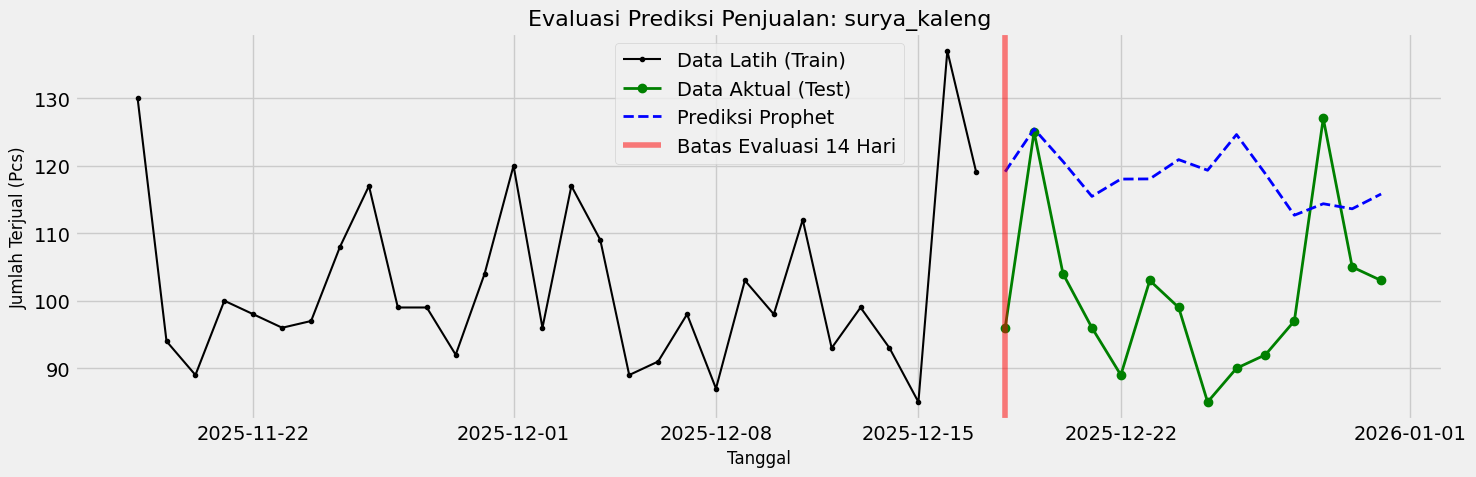

In [7]:
import matplotlib.pyplot as plt

# 1. AKTIFKAN TEMA CANTIKNYA DI SINI
plt.style.use('fivethirtyeight')
plt.rcParams['figure.figsize'] = (15, 5)

# 2. GABUNGKAN DATA EVALUASI
hasil_evaluasi = forecast[['ds', 'yhat']].merge(test_data[['ds', 'y']], on='ds')

plt.figure(figsize=(15, 5))

# 3. BATASI DATA HISTORIS 
historical_plot = train_data.iloc[-30:] 
plt.plot(historical_plot['ds'], historical_plot['y'], label='Data Latih (Train)', color='black', marker='.', linewidth=1.5)

# 4. PLOT DATA AKTUAL VS PREDIKSI (14 Hari)
plt.plot(hasil_evaluasi['ds'], hasil_evaluasi['y'], label='Data Aktual (Test)', color='green', marker='o', linewidth=2)
plt.plot(hasil_evaluasi['ds'], hasil_evaluasi['yhat'], label='Prediksi Prophet', color='blue', linestyle='--', linewidth=2)

# 5. GARIS PEMBATAS MERAH
plt.axvline(x=test_data['ds'].iloc[0], color='red', linestyle='-', alpha=0.5, label='Batas Evaluasi 14 Hari')

# 6. PERCANTIK LABEL
plt.title(f'Evaluasi Prediksi Penjualan: {sheet_name}', fontsize=16)
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Jumlah Terjual (Pcs)', fontsize=12)
plt.legend(loc='best')
plt.tight_layout()

# Tampilkan grafiknya!
plt.show()

### 7. FORECAST & PERHITUNGAN REORDER POINT (ROP)
Melatih model dengan keseluruhan data untuk memprediksi kebutuhan stok riil selama Lead Time ke depan.

In [8]:
# Latih ulang dengan df (seluruh data)
final_model = Prophet(
    changepoint_prior_scale=skala_terbaik, 
    yearly_seasonality=True, 
    weekly_seasonality=True
)
final_model.fit(df)

future_14_days = final_model.make_future_dataframe(periods=lead_time, freq='D')
final_forecast = final_model.predict(future_14_days)

# Ambil 14 hari paling akhir
forecast_14 = final_forecast.iloc[-lead_time:]

# --- PERHITUNGAN INVENTARIS ---
kebutuhan_stok = round(forecast_14['yhat'].sum())
safety_stock = round(mae * lead_time)
rekomendasi_pembelian = kebutuhan_stok + safety_stock

print("Kebutuhan stok 14 hari  :", kebutuhan_stok)
print("Safety Stock            :", safety_stock)
print("Rekomendasi pembelian   :", rekomendasi_pembelian)

23:46:46 - cmdstanpy - INFO - Chain [1] start processing
23:46:46 - cmdstanpy - INFO - Chain [1] done processing


Kebutuhan stok 14 hari  : 1472
Safety Stock            : 271
Rekomendasi pembelian   : 1743
